# Problema: Clases desbalanceadas

## SMOTE

In [28]:
# Si no está instalada la libreria
#  pip install imbalanced-learn

# Verificar la versión instalada
import imblearn
print(imblearn.__version__)

0.14.2


Creamos un datasets desbalanceado para ver como trabaja la técnia SMOTE

In [29]:
#Cargamos las librerías a utilizar
import imblearn
from collections import Counter
from sklearn.datasets import make_classification
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt
import pandas as pd

# Creamos el datasets de clasificación y 2 clases.
X, y = make_classification(n_samples=10000, n_features=2, n_redundant=0,
 n_clusters_per_class=1, weights=[0.99], flip_y=0, random_state=1)

In [30]:

# Contamos los valores de clase
counter = Counter(y)
print(counter)


Counter({np.int64(0): 9900, np.int64(1): 100})


Mostramos gráficamente los valores, para observar el desbalanceo.

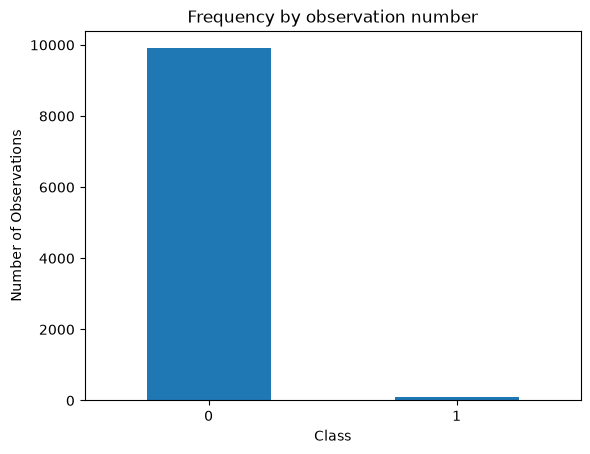

In [31]:

import pandas as pd

count_classes = pd.Series(y).value_counts(sort=True)
count_classes.plot(kind = 'bar', rot=0)

plt.title("Frequency by observation number")
plt.xlabel("Class")
plt.ylabel("Number of Observations");

Text(0, 0.5, 'Característica x2')

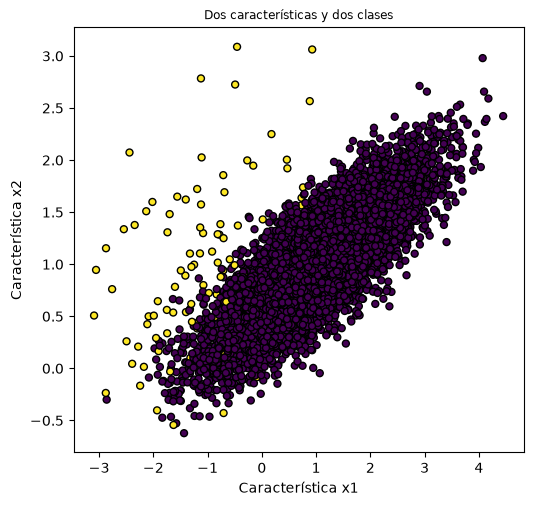

In [32]:
plt.figure(figsize=(5, 5))
plt.subplots_adjust(bottom=0.05, top=0.9, left=0.05, right=0.95)
x1 = X[:,0]
x2 = X[:,1]
plt.title("Dos características y dos clases", fontsize="small")
plt.scatter(x1, x2, marker="o", c=y, s=25, edgecolor="k")
plt.xlabel('Característica x1')
plt.ylabel('Característica x2')

A continuación, podemos sobremuestrear la clase minoritaria utilizando SMOTE.
La clase SMOTE actúa como un objeto de transformación de datos de scikit-learn en el sentido de que debe definirse y configurarse, ajustarse a un conjunto de datos y, a continuación, aplicarse para crear una nueva versión transformada del conjunto de datos.
Por ejemplo, podemos definir una instancia de SMOTE con parámetros predeterminados que equilibrarán la clase minoritaria y, a continuación, ajustarla y aplicarla en un solo paso para crear una versión transformada de nuestro conjunto de datos.


In [33]:

# transform the dataset
oversample = SMOTE()
X, y = oversample.fit_resample(X, y)

Una vez transformados, podemos resumir la distribución de clases del nuevo conjunto de datos transformado, que se espera que ahora esté equilibrado gracias a la creación de muchos ejemplos sintéticos nuevos en la clase minoritaria.

In [34]:

counter = Counter(y)
print(counter)

Counter({np.int64(0): 9900, np.int64(1): 9900})


Ahora mostramos gráficamente los ejemplos del nuevo dataset

Text(0, 0.5, 'Característica x2')

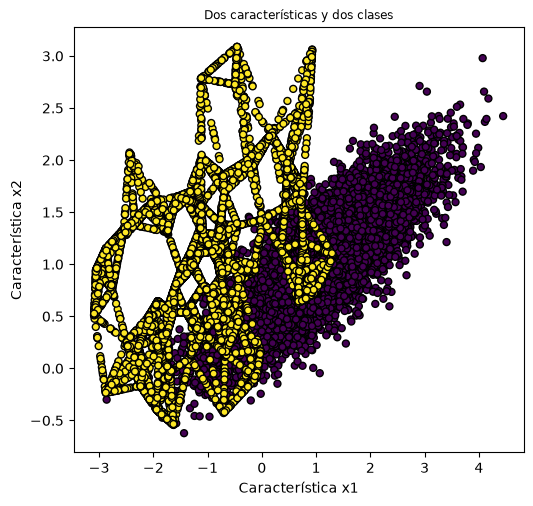

In [35]:
plt.figure(figsize=(5, 5))
plt.subplots_adjust(bottom=0.05, top=0.9, left=0.05, right=0.95)
x1 = X[:,0]
x2 = X[:,1]
plt.title("Dos características y dos clases", fontsize="small")
plt.scatter(x1, x2, marker="o", c=y, s=25, edgecolor="k")
plt.xlabel('Característica x1')
plt.ylabel('Característica x2')

Otra opción, sería realizar a la vez el SMOTE en la clase minoritaria y aplicar un muestreo de reducción aleatorio en la clase mayoritaria.

Counter({np.int64(0): 9900, np.int64(1): 100})
Counter({np.int64(0): 1980, np.int64(1): 990})


Text(0, 0.5, 'Característica x2')

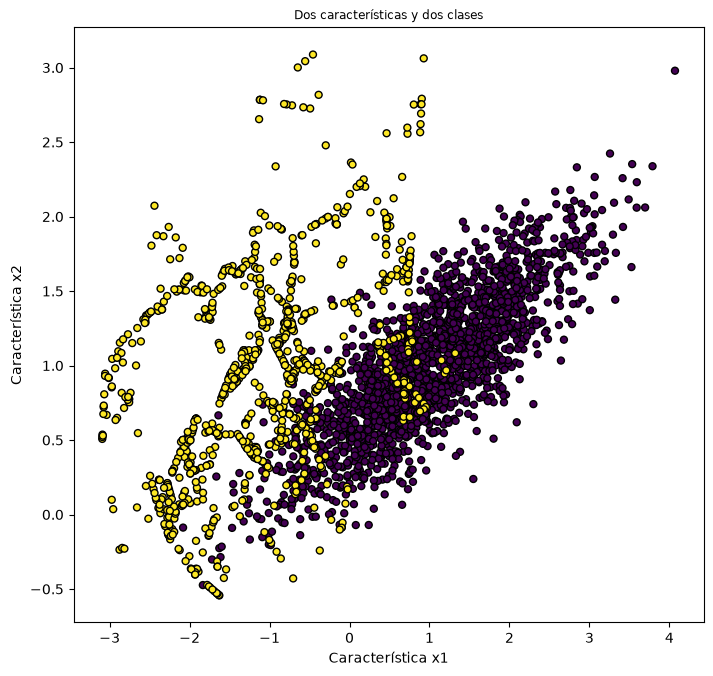

In [36]:
# Oversample with SMOTE and random undersample for imbalanced dataset
from collections import Counter
from sklearn.datasets import make_classification
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline
from matplotlib import pyplot

# Creamos un dataset inicial desbalanceado
X, y = make_classification(n_samples=10000, n_features=2, n_redundant=0,
	n_clusters_per_class=1, weights=[0.99], flip_y=0, random_state=1)
# Mostramos la distribución de datos inicial
counter = Counter(y)
print(counter)
# Definimos el pipeline de transformacones
over = SMOTE(sampling_strategy=0.1)
under = RandomUnderSampler(sampling_strategy=0.5)
steps = [('o', over), ('u', under)]
pipeline = Pipeline(steps=steps)
# Transformamos el datasets
X, y = pipeline.fit_resample(X, y)
# contamos la distribución de clases
counter = Counter(y)
print(counter)
# mostramos los ejemplos
plt.figure(figsize=(7, 7))
plt.subplots_adjust(bottom=0.05, top=0.9, left=0.05, right=0.95)
x1 = X[:,0]
x2 = X[:,1]
plt.title("Dos características y dos clases", fontsize="small")
plt.scatter(x1, x2, marker="o", c=y, s=25, edgecolor="k")
plt.xlabel('Característica x1')
plt.ylabel('Característica x2')

## Borderline-SMOTE

Una extensión popular de SMOTE consiste en seleccionar las instancias de la clase minoritaria que están mal clasificadas, como con un modelo de clasificación k-NN.

Counter({np.int64(0): 9900, np.int64(1): 100})
Counter({np.int64(0): 9900, np.int64(1): 9900})


Text(0, 0.5, 'Característica x2')

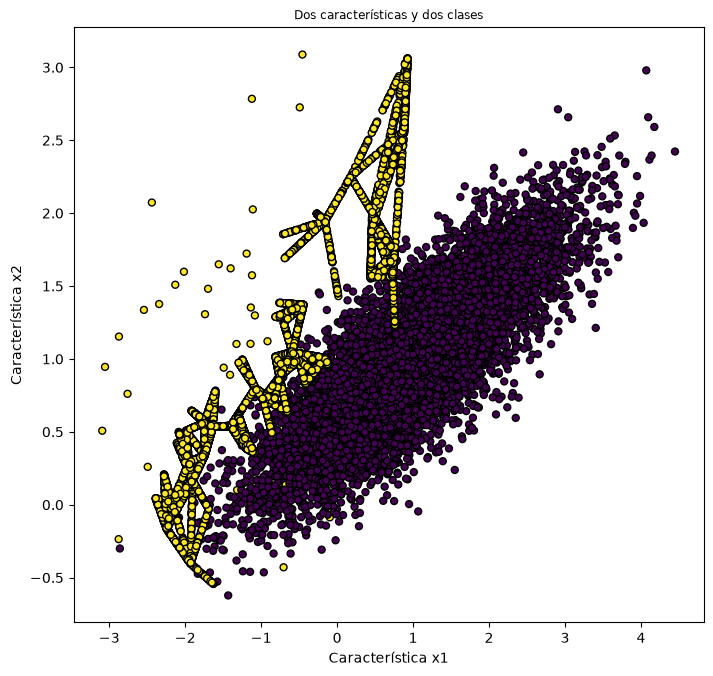

In [37]:
from collections import Counter
from sklearn.datasets import make_classification
from imblearn.over_sampling import BorderlineSMOTE
from matplotlib import pyplot

# Creamos un dataset desbalanceado
X, y = make_classification(n_samples=10000, n_features=2, n_redundant=0,
 n_clusters_per_class=1, weights=[0.99], flip_y=0, random_state=1)
# Mostramos la distribución de clases
counter = Counter(y)
print(counter)
# Transformamos el dataset
oversample = BorderlineSMOTE()
X, y = oversample.fit_resample(X, y)
# Mostramos la nueva distribución de clases
counter = Counter(y)
print(counter)
# Graficamos el resultado
plt.figure(figsize=(7, 7))
plt.subplots_adjust(bottom=0.05, top=0.9, left=0.05, right=0.95)
x1 = X[:,0]
x2 = X[:,1]
plt.title("Dos características y dos clases", fontsize="small")
plt.scatter(x1, x2, marker="o", c=y, s=25, edgecolor="k")
plt.xlabel('Característica x1')
plt.ylabel('Característica x2')

## Borderline-SMOTE SVM

Es una alternativa de Borderline-SMOTE en la que se utiliza un algoritmo SVM en lugar de un KNN para identificar ejemplos mal clasificados en el límite de decisión.

En este método  se utiliza un SVM para localizar el límite de decisión definido por los vectores de soporte y los ejemplos de la clase minoritaria que se acercan a los vectores de soporte se convierten en el foco para generar ejemplos sintéticos.

Counter({np.int64(0): 9900, np.int64(1): 100})
Counter({np.int64(0): 9900, np.int64(1): 9900})


Text(0, 0.5, 'Característica x2')

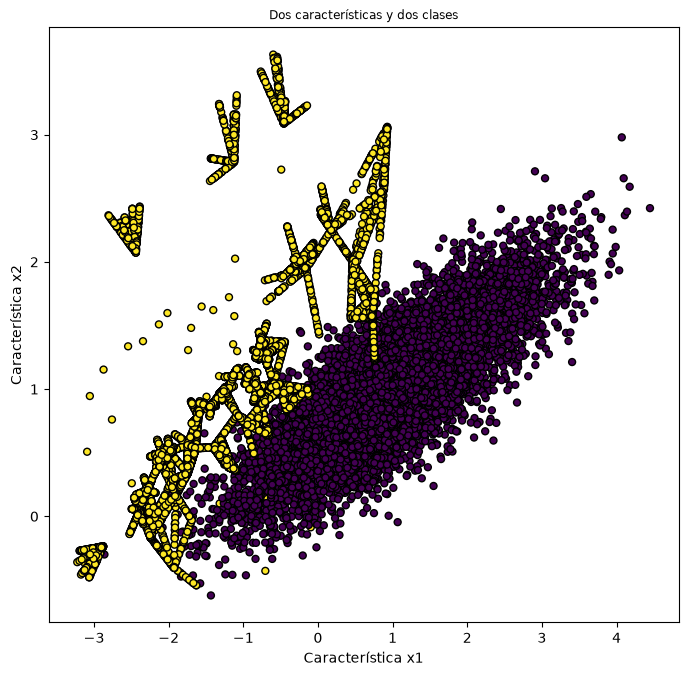

In [38]:
# borderline-SMOTE with SVM for imbalanced dataset
from collections import Counter
from sklearn.datasets import make_classification
from imblearn.over_sampling import SVMSMOTE
from matplotlib import pyplot

# Definimos el dataset
X, y = make_classification(n_samples=10000, n_features=2, n_redundant=0,
	n_clusters_per_class=1, weights=[0.99], flip_y=0, random_state=1)
# Mostramos la distribución de clases
counter = Counter(y)
print(counter)
# Transformamos el dataset
oversample = SVMSMOTE()
X, y = oversample.fit_resample(X, y)
# Mostramos la nueva distribución
counter = Counter(y)
print(counter)
# Graficamos el resultado
plt.figure(figsize=(7, 7))
plt.subplots_adjust(bottom=0.05, top=0.9, left=0.05, right=0.95)
x1 = X[:,0]
x2 = X[:,1]
plt.title("Dos características y dos clases", fontsize="small")
plt.scatter(x1, x2, marker="o", c=y, s=25, edgecolor="k")
plt.xlabel('Característica x1')
plt.ylabel('Característica x2')

## Adaptive Synthetic Sampling (ADASYN)

Otro enfoque consiste en generar muestras sintéticas inversamente proporcionales a la densidad de los ejemplos de la clase minoritaria. Esto significa, generar más ejemplos sintéticos en regiones del espacio de características donde la densidad de ejemplos minoritarios es baja, y menos o ninguno donde la densidad es alta.

Counter({np.int64(0): 9900, np.int64(1): 100})
Counter({np.int64(0): 9900, np.int64(1): 9899})


Text(0, 0.5, 'Característica x2')

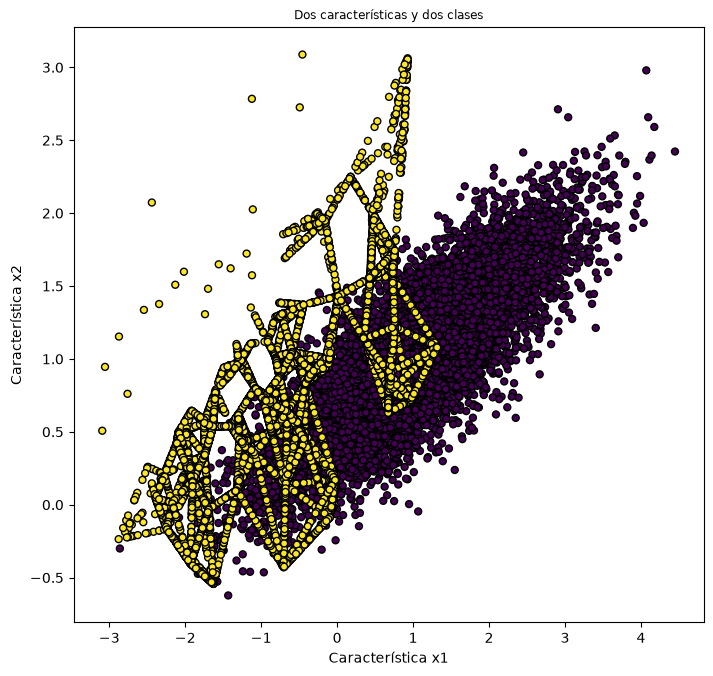

In [39]:
# Oversample and plot imbalanced dataset with ADASYN
from collections import Counter
from sklearn.datasets import make_classification
from imblearn.over_sampling import ADASYN
from matplotlib import pyplot

# Definimos el dataset
X, y = make_classification(n_samples=10000, n_features=2, n_redundant=0,
	n_clusters_per_class=1, weights=[0.99], flip_y=0, random_state=1)
# Mostramos la distribución de clases
counter = Counter(y)
print(counter)
# Transformamos el datasets
oversample = ADASYN()
X, y = oversample.fit_resample(X, y)
# Mostramos la nueva distribución de clases
counter = Counter(y)
print(counter)
# Graficamos las clases
plt.figure(figsize=(7, 7))
plt.subplots_adjust(bottom=0.05, top=0.9, left=0.05, right=0.95)
x1 = X[:,0]
x2 = X[:,1]
plt.title("Dos características y dos clases", fontsize="small")
plt.scatter(x1, x2, marker="o", c=y, s=25, edgecolor="k")
plt.xlabel('Característica x1')
plt.ylabel('Característica x2')

Otras variantes de SMOTE: 
- KMeansSMOTE: https://imbalanced-learn.org/stable/references/generated/imblearn.over_sampling.KMeansSMOTE.html#imblearn.over_sampling.KMeansSMOTE
- SMOTENC: https://imbalanced-learn.org/stable/references/generated/imblearn.over_sampling.SMOTENC.html#imblearn.over_sampling.SMOTENC

## Simulación de ROSE

In [40]:
from sklearn.datasets import make_classification
from imblearn.over_sampling import RandomOverSampler
from collections import Counter
# Definimos el dataset
X, y = make_classification(n_samples=5000, n_features=2, n_informative=2,
                           n_redundant=0, n_repeated=0, n_classes=3,
                           n_clusters_per_class=1,
                           weights=[0.01, 0.05, 0.94],
                           class_sep=0.8, random_state=0)
#Aplicamos el método
ros = RandomOverSampler(random_state=0)
X_resampled, y_resampled = ros.fit_resample(X, y)
#Contamos la distribución de clases
print(sorted(Counter(y_resampled).items()))

[(np.int64(0), 4674), (np.int64(1), 4674), (np.int64(2), 4674)]


Además, RandomOverSampler permite muestrear datos heterogéneos (por ejemplo, que contengan algunas cadenas). Incluso trabajar con pandas.

In [41]:
from sklearn.datasets import fetch_openml
df_adult, y_adult = fetch_openml(
    'adult', version=2, as_frame=True, return_X_y=True)
df_adult.head()  
df_resampled, y_resampled = ros.fit_resample(df_adult, y_adult)
df_resampled.head()  

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States


Si la repetición de muestras es un problema, el parámetro 'shrinkage' permite crear un bootstrap suavizado. Sin embargo, los datos originales deben ser numéricos. El parámetro 'shrinkage' controla la dispersión de las nuevas muestras generadas. Utilizando boostrap estamos utilizando la técnica Ejemplos de Sobremuestreo Aleatorio (ROSE)

## Under sampling técnicas

Técnicas que permiten reducir la clase mayoritaria, técnicas de selección de instancias:
- CondensedNearestNeighbour
- EditedNearestNeighbours
- RepeatedEditedNearestNeighbours
- AllKNN 
- InstanceHardnessThreshold
- NearMiss
- NeighbourhoodCleaningRule
- OneSidedSelection
- RandomUnderSampler
- TomekLinks

## Clasificación de 1 única clase (One-Class learning)

Este algoritmo se suele utilizar para detectar datos anómalos. Sin embargo, también puede tener un enfoque para clasificar aquellas instancias de la clase minoritaria en un desbalanceo. 

#### Técnica One Class SVM

La principal diferencia con una SVM estándar es que se ajusta de forma no supervisada y no proporciona los hiperparámetros normales para ajustar el margen como C. En su lugar, proporciona un hiperparámetro «nu» que controla la sensibilidad de los vectores de soporte y debe ajustarse a la proporción aproximada de valores atípicos en los datos, por ejemplo, 0.01%. Al modelar una clase, el algoritmo captura la densidad de la clase mayoritaria y clasifica los ejemplos en los extremos de la función de densidad como valores atípicos. 

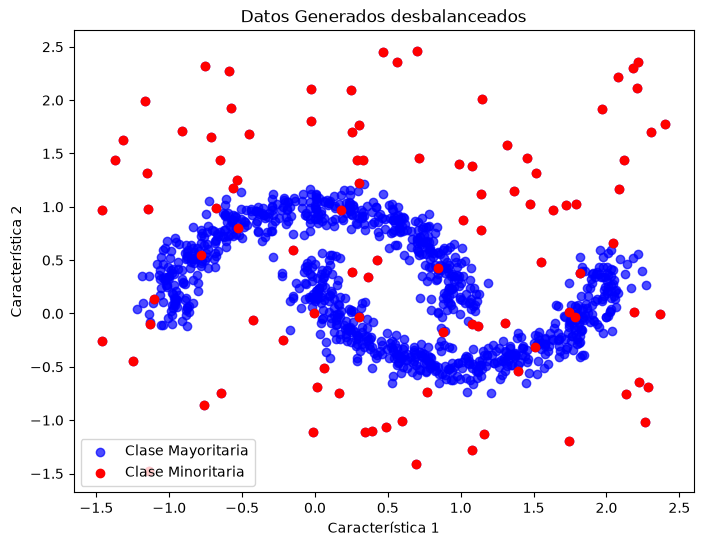

In [42]:
# Vamos a crear un datasets desbalanceado
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.svm import OneClassSVM
# Generar datos sintéticos con make_moons
X, _ = make_moons(n_samples=1000, noise=0.1, random_state=42)
# Introducir algunas anomalías
anomalies = np.random.uniform(low=-1.5, high=2.5, size=(100, 2))
# Combinar datos normales y anomalías
data = np.vstack([X, anomalies])
# Visualizar los datos con las anomalías en un color diferente
plt.figure(figsize=(8, 6))
plt.scatter(data[:, 0], data[:, 1], alpha=0.7, c='blue', label='Clase Mayoritaria')
plt.scatter(anomalies[:, 0], anomalies[:, 1], color='red', label='Clase Minoritaria')
plt.xlabel('Característica 1')
plt.ylabel('Característica 2')
plt.title('Datos Generados desbalanceados')
plt.legend()
plt.show()

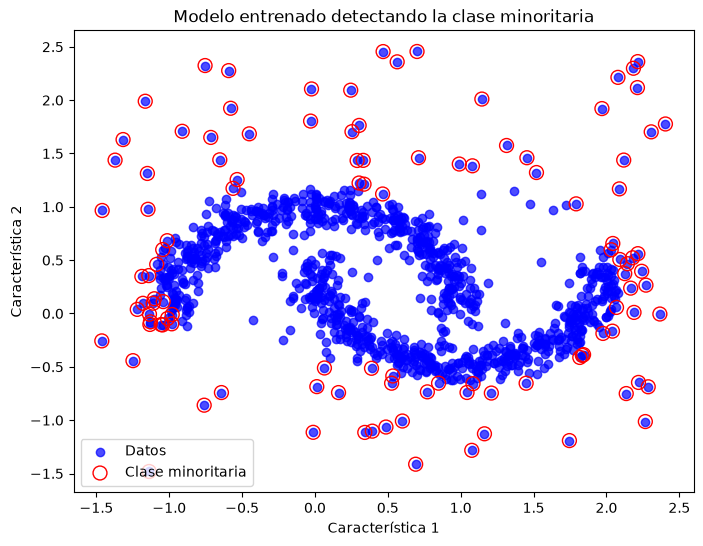

In [43]:
# Entrenar el modelo
model = OneClassSVM(kernel='rbf', nu=0.10, gamma='auto')
model.fit(data)
# Predecir anomalías
predictions = model.predict(data)
# Visualizar los resultados con círculos sobre las anomalías
plt.figure(figsize=(8, 6))
plt.scatter(data[:, 0], data[:, 1], alpha=0.7, c='blue', label='Datos')
plt.scatter(data[predictions == -1][:, 0], data[predictions == -1][:, 1],
            facecolors='none', edgecolors='r', s=100, label='Clase minoritaria')
plt.xlabel('Característica 1')
plt.ylabel('Característica 2')
plt.title('Modelo entrenado detectando la clase minoritaria')
plt.legend()
plt.show()

En lugar de utilizar el predict y dejar que la técnica decida, se pueden observar que valores se devuelven y decidir en función de dicho valor. Por ejemplo, sería interesante poder utilizar la lógica fuzzy para proponer una técnica de decisión imprecisa.

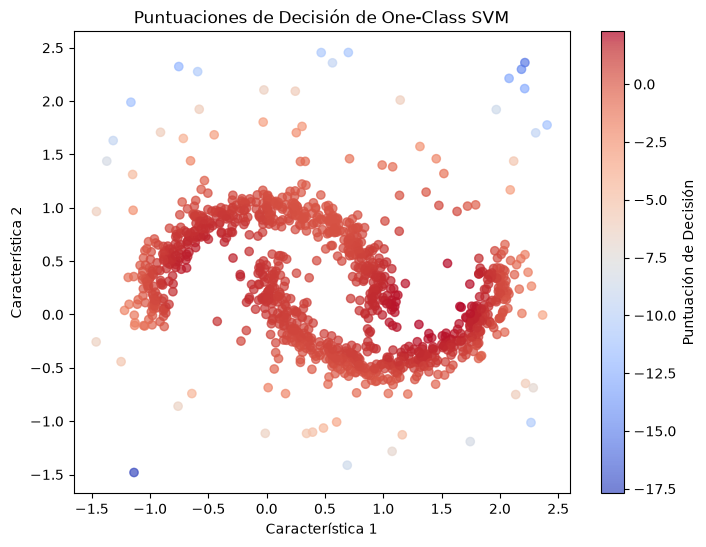

In [44]:
# Obtener la puntuación de decisión para cada punto en el conjunto de datos
decision_scores = model.decision_function(data)
# Visualizar las puntuaciones de decisión
plt.figure(figsize=(8, 6))
plt.scatter(data[:, 0], data[:, 1], c=decision_scores, cmap='coolwarm', alpha=0.7)
plt.colorbar(label='Puntuación de Decisión')
plt.xlabel('Característica 1')
plt.ylabel('Característica 2')
plt.title('Puntuaciones de Decisión de One-Class SVM')
plt.show()

#### Isolation Forest

El modelo Isolation Forest es un ensamble que se forma al combinar varios isolation tree, cada uno entrenado con una muestra diferente obtenida mediante bootstrapping (bagging) de los datos originales. El valor predicho para cada observación corresponde al número promedio de divisiones requeridas para aislarla dentro del conjunto de árboles. Un valor menor indica una mayor probabilidad de que la observación sea una anomalía. A menudo, se utiliza el término "distancia" para referirse a este número promedio de divisiones. 

En Scikit Learn, al entrenar el modelo, se tiene que especificar el porcentaje de anomalías que se espera en los datos de entrenamiento (contamination). Con este valor, el modelo aprende el valor a partir del cual una observación se considera anomalía. Al aplicar el método predict() se obtiene -1 si es anomalía (outlier) o 1 si es un dato normal (inliers). Para recuperar la métrica de anomalía en lugar de la clasificación, hay que emplear el método score_samples().

In [45]:
# Tratamiento de datos
# ==============================================================================
import numpy as np
import pandas as pd
from sklearn.datasets import make_blobs

# Gráficos
# ==============================================================================
import matplotlib.pyplot as plt
from matplotlib import style
import seaborn as sns
#style.use('ggplot') or plt.style.use('ggplot')

# Preprocesado y modelado
# ==============================================================================
from sklearn.ensemble import IsolationForest
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Definición y entrenamiento del modelo IsolationForest
# ==============================================================================

####### UTILIZAMOS LOS DATOS ANTERIORES######
modelo_isof = IsolationForest(
                n_estimators  = 1000,
                max_samples   ='auto',
                contamination = 0.10,
                random_state  = 123,
            )

modelo_isof.fit(X=data)

ModuleNotFoundError: No module named 'seaborn'

In [ ]:
# Predicción clasificación
# ==============================================================================
predictions = modelo_isof.predict(X=data)
predictions

array([ 1,  1,  1, ...,  1,  1, -1])

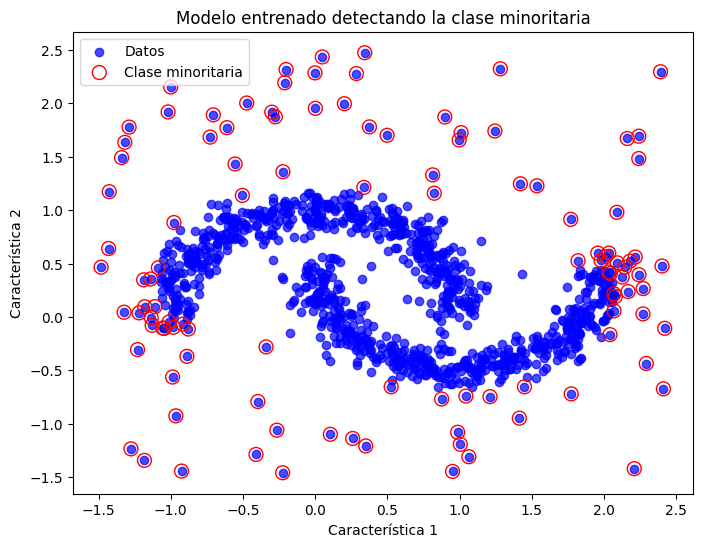

In [ ]:
predictions = modelo_isof.predict(data)
# Visualizar los resultados con círculos sobre las anomalías
plt.figure(figsize=(8, 6))
plt.scatter(data[:, 0], data[:, 1], alpha=0.7, c='blue', label='Datos')
plt.scatter(data[predictions == -1][:, 0], data[predictions == -1][:, 1],
            facecolors='none', edgecolors='r', s=100, label='Clase minoritaria')
plt.xlabel('Característica 1')
plt.ylabel('Característica 2')
plt.title('Modelo entrenado detectando la clase minoritaria')
plt.legend()
plt.show()

In [ ]:
# Si se quiere mostrar las librerias con las que se ha ejecutado
# pip install sinfo
from sinfo import sinfo
sinfo()

The `sinfo` package has changed name and is now called `session_info` to become more discoverable and self-explanatory. The `sinfo` PyPI package will be kept around to avoid breaking old installs and you can downgrade to 0.3.2 if you want to use it without seeing this message. For the latest features and bug fixes, please install `session_info` instead. The usage and defaults also changed slightly, so please review the latest README at https://gitlab.com/joelostblom/session_info.
-----
imblearn    0.12.4
matplotlib  3.8.2
numpy       1.26.2
pandas      2.1.4
seaborn     0.13.2
sinfo       0.3.4
sklearn     1.4.0
-----
IPython             8.18.1
jupyter_client      8.6.0
jupyter_core        5.5.0
-----
Python 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
Windows-10-10.0.26100-SP0
20 logical CPU cores, Intel64 Family 6 Model 151 Stepping 2, GenuineIntel
-----
Session information updated at 2025-10-13 10:25


RETO

Aplicar el dataset Glass (ver archivo glass.zip) y aplicar al menos 3 técnicas de balanceo de datos. Utilizando una misma técnica de Machine Learning (SVM, árbol de decisión, MLP, KNN), obtén 3 métricas que indiquen cuál es el mejor método de balanceo de datos.

PISTA: Glass, puede pasarse a un dataset binario inicialmente para poder analizarlo más sencillo al inicio.

In [ ]:
import pandas as pd

# Definir las columnas a partir del archivo glass.names
columnas = [
    'Id',
    'RI',
    'Na',
    'Mg',
    'Al',
    'Si',
    'K',
    'Ca',
    'Ba',
    'Fe',
    'Type'
]

# Cargar los datos del archivo .data (sin cabecera)
ruta_glass = './glass+identification/glass.data'
df_glass = pd.read_csv(ruta_glass, names=columnas, index_col=False)

# Opcional: eliminar la columna Id si no es necesaria
df_glass = df_glass.drop(columns=['Id'])

# Inspeccionar las primeras filas
df_glass

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.00,0.0,1
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.00,0.0,1
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.00,0.0,1
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.00,0.0,1
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.00,0.0,1
...,...,...,...,...,...,...,...,...,...,...
209,1.51623,14.14,0.00,2.88,72.61,0.08,9.18,1.06,0.0,7
210,1.51685,14.92,0.00,1.99,73.06,0.00,8.40,1.59,0.0,7
211,1.52065,14.36,0.00,2.02,73.42,0.00,8.44,1.64,0.0,7
212,1.51651,14.38,0.00,1.94,73.61,0.00,8.48,1.57,0.0,7


In [47]:
# 1 = cristal de ventana (tipos 1,2,3); 0 = no ventana (5,6,7)
df_glass["cristal"] = df_glass["Type"].isin([1, 2, 3]).astype(int)
print(df_glass["cristal"].value_counts())

df_glass["Type"] = df_glass["Type"].astype("category")


df_glass



cristal
1    163
0     51
Name: count, dtype: int64


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type,cristal,Type_cat
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.00,0.0,1,1,1
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.00,0.0,1,1,1
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.00,0.0,1,1,1
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.00,0.0,1,1,1
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.00,0.0,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...
209,1.51623,14.14,0.00,2.88,72.61,0.08,9.18,1.06,0.0,7,0,7
210,1.51685,14.92,0.00,1.99,73.06,0.00,8.40,1.59,0.0,7,0,7
211,1.52065,14.36,0.00,2.02,73.42,0.00,8.44,1.64,0.0,7,0,7
212,1.51651,14.38,0.00,1.94,73.61,0.00,8.48,1.57,0.0,7,0,7


In [48]:
# División de los datos en conjuntos de entrenamiento y prueba

from sklearn.model_selection import train_test_split

# Seleccionamos las características (features) y la variable objetivo (target)
X = df_glass.drop(columns=["cristal", "Type"])
y = df_glass["cristal"]

# Separación: 70% entrenamiento, 30% prueba (puedes ajustar test_size si prefieres otro porcentaje)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.3, 
    random_state=42,     # Para reproducibilidad del experimento
    stratify=y           # Para mantener proporciones de clases en train y test
)

# Verificamos el tamaño de los subconjuntos
print("Tamaño conjunto de entrenamiento:", X_train.shape)
print("Tamaño conjunto de prueba:", X_test.shape)
print("Distribución en entrenamiento:\n", y_train.value_counts())
print("Distribución en prueba:\n", y_test.value_counts())

Tamaño conjunto de entrenamiento: (149, 10)
Tamaño conjunto de prueba: (65, 10)
Distribución en entrenamiento:
 cristal
1    113
0     36
Name: count, dtype: int64
Distribución en prueba:
 cristal
1    50
0    15
Name: count, dtype: int64


In [49]:
# Aplicamos SMOTE para sobremuestreo de la clase minoritaria
from imblearn.over_sampling import SMOTE

# Creamos el objeto SMOTE
smote = SMOTE(random_state=42)

# Aplicamos a los datos de entrenamiento
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# Verificamos la nueva distribución de las clases en el set de entrenamiento
print("Distribución tras SMOTE en entrenamiento:\n", y_train_smote.value_counts())

Distribución tras SMOTE en entrenamiento:
 cristal
0    113
1    113
Name: count, dtype: int64


In [ ]:
# borderline-SMOTE with SVM for imbalanced dataset
from collections import Counter
from sklearn.datasets import make_classification
from imblearn.over_sampling import SVMSMOTE
from matplotlib import pyplot

# Generamos x,y basados en el dataset de glass
X = glass_train.drop(columns=['cristal']).values
y = glass_train['cristal'].values

# Mostramos la distribución de clases
counter = Counter(y)
print(counter)

Distribución tras RandomUnderSampler en entrenamiento:
 Counter({0: 36, 1: 36})


In [53]:
# Aplicar RandomUnderSampler al conjunto de entrenamiento original
from imblearn.under_sampling import RandomUnderSampler
from collections import Counter

# Usar los mismos datos de entrenamiento (X_train, y_train)
rus = RandomUnderSampler(random_state=42)

X_train_rus, y_train_rus = rus.fit_resample(X_train, y_train)

# Mostrar la nueva distribución de clases tras resampling
print("Distribución tras RandomUnderSampler en entrenamiento:\n", Counter(y_train_rus))

Distribución tras RandomUnderSampler en entrenamiento:
 Counter({0: 36, 1: 36})


In [50]:
# Aplicar Random Forest y evaluar con 3 métricas

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score

# Creamos el modelo de Random Forest
clf = RandomForestClassifier(random_state=42)

# Entrenamos el modelo usando los datos sobremuestreados por SMOTE
clf.fit(X_train_smote, y_train_smote)

# Predecimos sobre el conjunto de prueba original
y_pred = clf.predict(X_test)

# Calculamos tres métricas: accuracy, precision y recall
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)

print(f'Accuracy: {accuracy:.3f}')
print(f'Precision: {precision:.3f}')
print(f'Recall: {recall:.3f}')

Accuracy: 1.000
Precision: 1.000
Recall: 1.000
